# Early Stopping 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week06/early_stopping/lab/early_stopping.ipynb)

오래 학습할수록 좋을까? 손글씨 숫자로 학습 곡선을 그리고, 참을성 있는 조기 종료를 직접 구현한다.

- **파트 1**: 슬라이드 실험 재현 (500장, 정답 20% 바꿈, 300번 학습)
- **파트 2**: 조기 종료 직접 구현 → 41번째에 멈추고 31번째로 되돌리기
- **파트 3**: 정답을 안 바꾸면? scikit-learn `early_stopping=True`

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 1 은 1~2분 걸린다.

In [ ]:
import copy, warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings("ignore")

## 파트 1. 학습 곡선

학습 500장 · 검증 500장. 학습 그림의 20% (100장) 정답을 일부러 다른 숫자로 바꾼다 (실제 데이터의 라벨 실수 흉내).

In [ ]:
X, y = load_digits(return_X_y=True)
X = X / 16                                                # pixel values 0..16 -> 0..1
rng = np.random.default_rng(0)
idx = rng.permutation(len(y))
tr, va = idx[:500], idx[500:1000]
flip = rng.choice(500, 100, replace=False)                # 100 training images get a wrong label
y_tr = y[tr].copy()
y_tr[flip] = (y_tr[flip] + rng.integers(1, 10, 100)) % 10
print("wrong labels:", int((y_tr != y[tr]).sum()))

def train_curves(X_tr, y_tr, X_va, y_va, epochs):
    model = MLPClassifier(hidden_layer_sizes=(256,), learning_rate_init=1e-3, random_state=0)
    acc_tr, acc_va, snapshots = [], [], []
    for _ in range(epochs):
        model.partial_fit(X_tr, y_tr, classes=np.arange(10))     # one more pass over the data
        acc_tr.append(model.score(X_tr, y_tr))
        acc_va.append(None)  # TODO: accuracy on the validation set
        snapshots.append(copy.deepcopy(model))
    return np.array(acc_tr), np.array(acc_va), snapshots

acc_tr, acc_va, snaps = train_curves(X[tr], y_tr, X[va], y[va], epochs=300)
best = int(np.argmax(acc_va)) + 1
print(f"best epoch {best}: val {acc_va[best - 1]:.2f}   epoch 300: train {acc_tr[-1]:.2f}, val {acc_va[-1]:.2f}")
plt.plot(acc_tr, label="train"); plt.plot(acc_va, label="validation"); plt.axvline(best - 1, ls="--", color="gray")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.show()

**예상 결과**

```
wrong labels: 100
best epoch 31: val 0.92   epoch 300: train 0.97, val 0.83
```

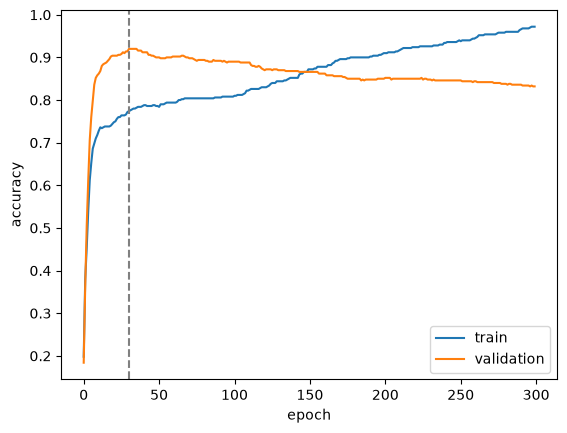

## 파트 2. 참을성 있는 조기 종료

최고 기록이 나오면 저장하고 기다림을 0 으로. 못 깨면 기다림 +1, 참을성만큼 기다렸으면 멈춘다.

In [ ]:
def early_stop(val_scores, patience):
    best_score, best_epoch, wait = -np.inf, 0, 0
    for epoch, score in enumerate(val_scores, start=1):
        if score > best_score:
            best_score, best_epoch, wait = score, epoch, 0
        else:
            wait = None  # TODO: one more epoch without improvement
            if wait == patience:
                return epoch, best_epoch                  # (stopped at, restore this one)
    return len(val_scores), best_epoch

for p in [1, 3, 5, 10, 50]:
    stopped, restore = early_stop(acc_va, p)
    print(f"patience {p:2d}: stop at {stopped:3d}, restore epoch {restore:3d}  (val {acc_va[restore - 1]:.2f})")

stopped, restore = early_stop(acc_va, 10)
final = snaps[restore - 1]                                # the saved model
test = idx[1000:]                                         # never used above
print(f"\nrestored model on the untouched test set ({len(test)} images): {final.score(X[test], y[test]):.3f}")
print(f"epoch-300 model on the same test set: {snaps[-1].score(X[test], y[test]):.3f}")

**예상 결과**

```
patience  1: stop at  21, restore epoch  20  (val 0.90)
patience  3: stop at  23, restore epoch  20  (val 0.90)
patience  5: stop at  36, restore epoch  31  (val 0.92)
patience 10: stop at  41, restore epoch  31  (val 0.92)
patience 50: stop at  81, restore epoch  31  (val 0.92)

restored model on the untouched test set (797 images): 0.902
epoch-300 model on the same test set: 0.822
```

## 파트 3. 정답을 안 바꾸면? 라이브러리의 조기 종료

In [ ]:
acc_tr_c, acc_va_c, _ = train_curves(X[tr], y[tr], X[va], y[va], epochs=150)
plt.plot(acc_tr_c, label="train (clean labels)"); plt.plot(acc_va_c, label="validation")
plt.xlabel("epoch"); plt.legend(); plt.show()
print(f"clean labels: best val {acc_va_c.max():.3f} at epoch {int(np.argmax(acc_va_c)) + 1}, val at 150 = {acc_va_c[-1]:.3f}")

# scikit-learn holds out 10% of the training data and stops after n_iter_no_change epochs without improvement
auto = MLPClassifier(hidden_layer_sizes=(256,), early_stopping=True, validation_fraction=0.1,
                     n_iter_no_change=10, max_iter=300, random_state=0).fit(X[tr], y_tr)
print(f"sklearn early_stopping: stopped after {auto.n_iter_} epochs, test accuracy {auto.score(X[test], y[test]):.3f}")

**예상 결과**

```
clean labels: best val 0.954 at epoch 99, val at 150 = 0.952
sklearn early_stopping: stopped after 21 epochs, test accuracy 0.876
```

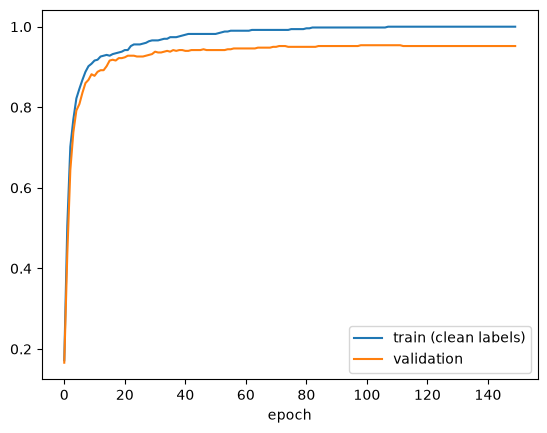

**확인 질문**
1. 파트 1 에서 31번째와 300번째 모델은 틀린 정답 100장에 각각 몇 장을 '틀린 정답대로' 답하나? (`snaps[30].predict(X[tr][flip]) == y_tr[flip]`)
2. 파트 2 의 시험 정확도는 검증 정확도 92% 와 비슷한가? 왜 조금 다를 수 있나?
3. 파트 3 에서 정답이 깨끗하면 검증 곡선이 떨어지는 정도가 어떻게 다른가?
4. 파트 3 의 scikit-learn 은 검증 데이터를 어디서 가져오나? 우리 파트 2 와 무엇이 다른가?

데이터 출처: Alpaydin & Kaynak, Optical Recognition of Handwritten Digits, UCI (scikit-learn `load_digits`).